# Exploratory Data Analysis (EDA)

Overview of the dataset: data quality, genre balance, lyrical length, and vocabulary.


## 1. Setup


In [1]:
# Install dependencies if needed
!pip install seaborn matplotlib pandas scikit-learn


In [2]:
import os
import sys
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# add project root to path
project_root = os.path.abspath('..')
if project_root not in sys.path:
    sys.path.append(project_root)

from utils.pipeline import (
    clean_for_classification, 
    plot_term_frequency, 
    cooccurrence_matrix_sentence_generator
)
from sklearn.feature_extraction.text import CountVectorizer

# plot styling
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 11


## 2. Dataset Description & Loading


In [3]:
# locate dataset directory
possible_dirs = ['../dataset', 'dataset', '../datasets', 'datasets']
data_dir = next((d for d in possible_dirs if os.path.exists(d)), None)

if data_dir is None:
    raise FileNotFoundError("Could not locate dataset folder. Check directory structure.")

print(f"Loading data from: {os.path.abspath(data_dir)}")

train_df = pd.read_csv(os.path.join(data_dir, 'train.csv'))
test_df = pd.read_csv(os.path.join(data_dir, 'test.csv'))

print(f"Training split: {train_df.shape[0]:,} rows × {train_df.shape[1]} columns")
print(f"Testing split:  {test_df.shape[0]:,} rows × {test_df.shape[1]} columns")


Loading data from: D:\Lean\season 5\Text Mining\Project\Text-Mining\dataset
Training split: 134,967 rows × 8 columns
Testing split:  33,742 rows × 7 columns


## 3. Data Quality Checks
Checking for missing values, duplicates, and invalid entries.


In [4]:
# 1. missing values
print("--- Missing Values ---")
print("Train nulls:")
print(train_df.isnull().sum()[train_df.isnull().sum() > 0])
print("\nTest nulls:")
print(test_df.isnull().sum()[test_df.isnull().sum() > 0] if test_df.isnull().any().any() else "No missing values in test set.")

# 2. duplicate checks
train_dup_ids = train_df['id'].duplicated().sum()
test_dup_ids = test_df['id'].duplicated().sum()
train_dup_songs = train_df.duplicated(subset=['title', 'artist']).sum()
test_dup_songs = test_df.duplicated(subset=['title', 'artist']).sum()

print("\n--- Duplicate Checks ---")
print(f"Duplicate IDs: Train = {train_dup_ids}, Test = {test_dup_ids}")
print(f"Duplicate (title, artist) pairs: Train = {train_dup_songs}, Test = {test_dup_songs}")

# 3. train/test ID overlap
id_overlap = len(set(train_df['id']).intersection(set(test_df['id'])))
print(f"Train/Test ID Overlap: {id_overlap} songs")

# 4. anomalous years
anomalous_years = train_df[train_df['year'] < 1900]
print(f"\n--- Anomalous Release Years (year < 1900) ---")
print(f"Count in train (year < 1900): {len(anomalous_years)}")
print(f"Count with year == 1: {(train_df['year'] == 1).sum()}")
print("Sample entries with year == 1:")
display(anomalous_years[['title', 'artist', 'year', 'tag']].head(5))

# 5. views summary statistics
print("\n--- Views Distribution Summary (Train) ---")
print(train_df['views'].describe())


--- Missing Values ---
Train nulls:
title    2
dtype: int64

Test nulls:
No missing values in test set.

--- Duplicate Checks ---
Duplicate IDs: Train = 0, Test = 0
Duplicate (title, artist) pairs: Train = 0, Test = 0
Train/Test ID Overlap: 0 songs

--- Anomalous Release Years (year < 1900) ---
Count in train (year < 1900): 653
Count with year == 1: 45
Sample entries with year == 1:

--- Views Distribution Summary (Train) ---
count    1.349670e+05
mean     3.413344e+03
std      4.192449e+04
min      0.000000e+00
25%      2.200000e+01
50%      8.900000e+01
75%      4.730000e+02
max      3.604497e+06
Name: views, dtype: float64


,title,artist,year,tag
4,Get Ready,John Campbell Munro,1,country
542,What Ought We To Do?,Gilbert and Sullivan,1879,misc
807,The Battle of Life Chap. 2,Charles Dickens,1846,misc
991,Paradiso: Canto 31,Dante Alighieri,1867,misc
2244,Machinery and Modern Industry Chap 1.15.3,Karl Marx,1867,misc


### Summary of Data Quality:
- **Missing values:** Only 2 missing titles in the train set; lyrics and genre tags have zero missing values. Test set has no missing values.
- **Duplicates:** No duplicate IDs and no overlap between train and test sets.
- **Year values:** 653 songs have release years before 1900, of which 45 are set to 1 (placeholder dates or ancient religious texts).
- **Views:** Highly skewed distribution (median is 89, max is over 3.6M), so a log scale will be needed for visualizations.


## 4. Genre Distribution


,Song Count,Percentage (%)
tag,,
pop,55742,41.30
rap,38584,28.59
rock,25332,18.77
rb,6203,4.60
misc,5640,4.18
country,3466,2.57


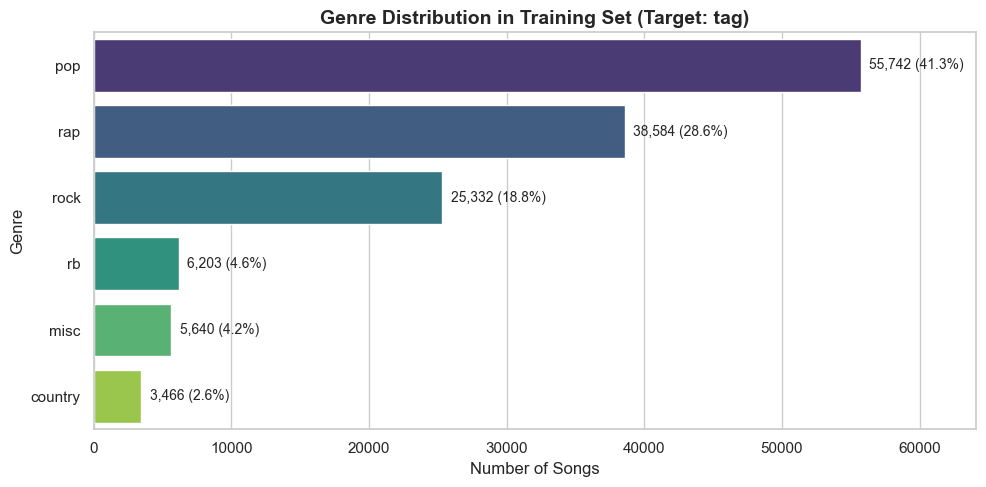

In [5]:
genre_counts = train_df['tag'].value_counts()
genre_pcts = train_df['tag'].value_counts(normalize=True) * 100

summary_table = pd.DataFrame({
    'Song Count': genre_counts,
    'Percentage (%)': genre_pcts.round(2)
})
display(summary_table)

plt.figure(figsize=(10, 5))
ax = sns.barplot(x=genre_counts.values, y=genre_counts.index, palette='viridis')
for i, (count, pct) in enumerate(zip(genre_counts.values, genre_pcts.values)):
    ax.text(count + 600, i, f"{count:,} ({pct:.1f}%)", va='center', fontsize=10)

plt.title('Genre Distribution in Training Set (Target: tag)', fontsize=14, weight='bold')
plt.xlabel('Number of Songs')
plt.ylabel('Genre')
plt.xlim(0, max(genre_counts.values) * 1.15)
plt.tight_layout()
plt.show()

### Genre Balance:
- `pop` (41.3%) and `rap` (28.6%) make up ~70% of the data; `country` is only ~2.6%.
- Because of this class imbalance, stratified splits and Macro-F1 evaluation will be necessary.


## 5. Lyrics Length Distribution


--- Overall Lyric Word Count Summary ---
count    134967.0
mean        317.6
std         451.5
min           1.0
25%         158.0
50%         244.0
75%         377.0
max       18221.0
Name: lyrics_word_count, dtype: float64

--- Word Count by Genre (Robust Summaries) ---


,count,median,mean,q25,q75
tag,,,,,
rap,38584,415.0,436.9,288.0,553.0
rb,6203,291.0,308.5,199.0,394.0
misc,5640,258.0,974.0,116.0,828.8
country,3466,217.0,232.4,161.0,284.0
pop,55742,205.0,227.3,141.0,287.0
rock,25332,188.0,202.4,131.0,256.0


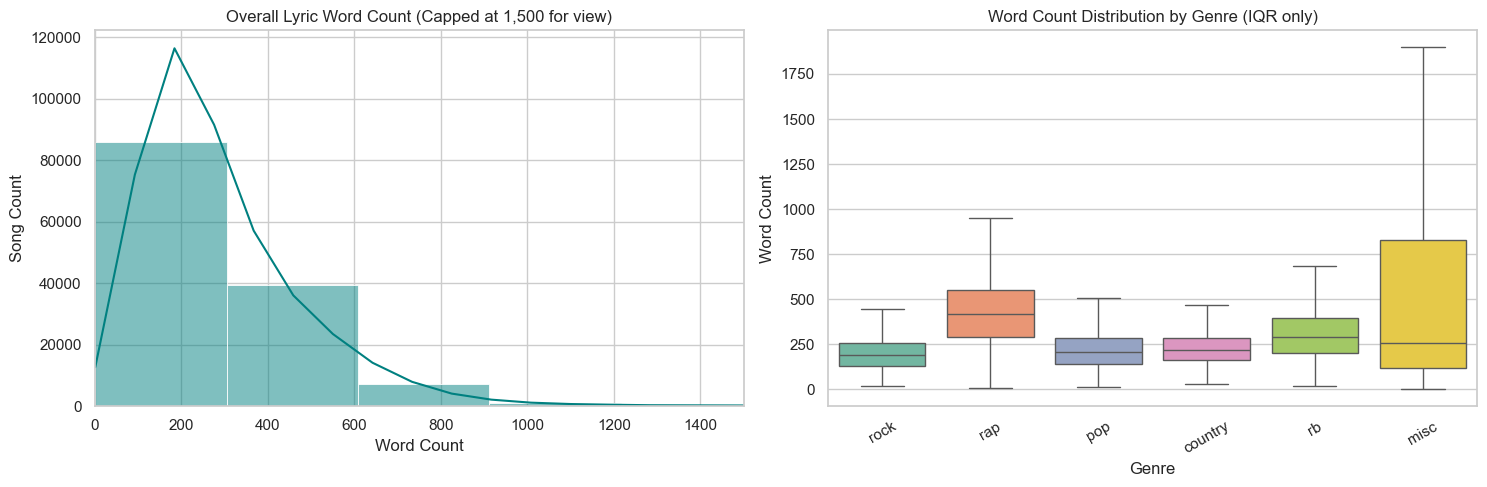

In [6]:
train_df['lyrics_word_count'] = train_df['lyrics'].astype(str).apply(lambda x: len(x.split()))

# Summary statistics overall and by genre
print("--- Overall Lyric Word Count Summary ---")
print(train_df['lyrics_word_count'].describe().round(1))

genre_word_stats = train_df.groupby('tag')['lyrics_word_count'].agg(
    count='count',
    median='median',
    mean='mean',
    q25=lambda x: np.percentile(x, 25),
    q75=lambda x: np.percentile(x, 75)
).round(1).sort_values(by='median', ascending=False)

print("\n--- Word Count by Genre (Robust Summaries) ---")
display(genre_word_stats)

# Visualizing distributions
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Distribution up to 1,500 words
sns.histplot(train_df['lyrics_word_count'], bins=60, kde=True, ax=axes[0], color='teal')
axes[0].set_xlim(0, 1500)
axes[0].set_title('Overall Lyric Word Count (Capped at 1,500 for view)')
axes[0].set_xlabel('Word Count')
axes[0].set_ylabel('Song Count')

# Boxplot by Genre (excluding visual outliers for legible comparison)
sns.boxplot(data=train_df, x='tag', y='lyrics_word_count', ax=axes[1], palette='Set2', showfliers=False)
axes[1].set_title('Word Count Distribution by Genre (IQR only)')
axes[1].set_xlabel('Genre')
axes[1].set_ylabel('Word Count')
axes[1].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

### Lyric Lengths:
- Rap has the highest median word count (~415 words), while Rock has the lowest (~188 words).
- Outliers exist on both ends (a few songs with <10 words, and some with >3,000 words). Capping at 1,000 words during preprocessing helps prevent matrix bloat.


## 6. Song Structure Tags


Total section tags detected: 394,266
Unique tag names: 69,785

Top 12 Most Frequent Tags:
chorus         73730
verse 1        31715
verse 2        30109
?              20528
hook           14662
pre-chorus     14212
bridge         13996
outro          13869
intro          11566
verse           8598
verse 3         8461
post-chorus     3704
Name: count, dtype: int64


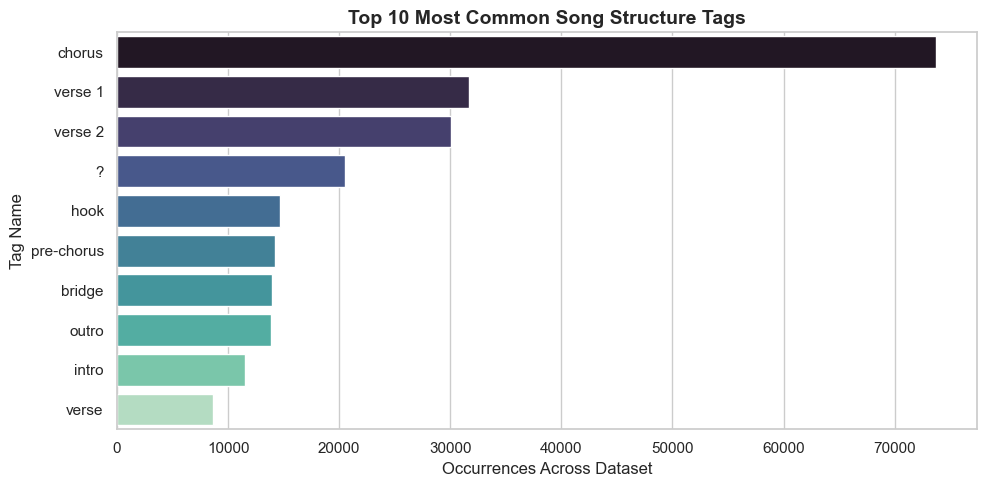

In [7]:
def extract_section_tags(text):
    return re.findall(r'\[(.*?)\]', str(text))

structure_tags_series = train_df['lyrics'].apply(extract_section_tags)
all_tags = [tag.strip().lower() for sublist in structure_tags_series for tag in sublist]
tag_series = pd.Series(all_tags)
tag_counts = tag_series.value_counts()

print(f"Total section tags detected: {len(all_tags):,}")
print(f"Unique tag names: {tag_series.nunique():,}")
print("\nTop 12 Most Frequent Tags:")
print(tag_counts.head(12))

plt.figure(figsize=(10, 5))
sns.barplot(x=tag_counts.head(10).values, y=tag_counts.head(10).index, palette='mako')
plt.title('Top 10 Most Common Song Structure Tags', fontsize=14, weight='bold')
plt.xlabel('Occurrences Across Dataset')
plt.ylabel('Tag Name')
plt.tight_layout()
plt.show()


- `[Chorus]` is by far the most frequent tag (>73k occurrences), followed by verses and bridges.
- Although `[Chorus]` appears frequently across the dataset, only ~28.2% of songs contain explicit `[Chorus]` markers.
- These tags should be stripped during standard cleaning so they don't count as words, but chorus sections can also be extracted as a separate feature.


## 7. Vocabulary Diversity & Character Encoding
We check lexical diversity (using a fixed-length window to keep it fair across songs) and character encoding to assess whether vocabulary density varies across genres (which informs term frequency weighting and normalization) and to verify whether non-ASCII characters pose encoding issues.


In [8]:
# sample 1,000 songs per genre for faster computation
sample_songs = pd.concat([
    g.sample(min(len(g), 1000), random_state=42)
    for _, g in train_df.groupby('tag')
]).copy()

def compute_standardized_ttr(text, sample_length=150):
    words = str(text).lower().split()
    if len(words) < sample_length:
        if len(words) == 0:
            return np.nan
        return len(set(words)) / len(words)
    # sub-sample to fixed token window
    sub_words = words[:sample_length]
    return len(set(sub_words)) / sample_length

sample_songs['std_ttr'] = sample_songs['lyrics'].apply(compute_standardized_ttr)
ttr_summary = sample_songs.groupby('tag')['std_ttr'].agg(['median', 'mean']).sort_values(by='median', ascending=False)

print("--- Standardized Lexical Diversity (TTR at 150-word window) ---")
display(ttr_summary.round(3))

# non-ASCII character proportion
def non_ascii_ratio(text):
    s = str(text)
    if not s:
        return 0.0
    return sum(1 for c in s if ord(c) > 127) / len(s)

train_df['non_ascii_ratio'] = train_df['lyrics'].apply(non_ascii_ratio)
high_non_ascii = train_df[train_df['non_ascii_ratio'] > 0.15]
print(f"\nSongs with > 15% non-ASCII characters: {len(high_non_ascii)} ({len(high_non_ascii)/len(train_df)*100:.2f}%)")


--- Standardized Lexical Diversity (TTR at 150-word window) ---

Songs with > 15% non-ASCII characters: 38 (0.03%)


,median,mean
tag,,
misc,0.687,0.674
rap,0.653,0.635
country,0.582,0.574
rock,0.580,0.577
rb,0.567,0.558
pop,0.560,0.551


- `pop` and `rb` show slightly lower lexical diversity due to repetitive choruses, while `rock` and `misc` have higher diversity.
- Over 99.9% of the characters are standard ASCII, so standard tokenizers and lemmatizers will work without decoding issues.


## 8. Term Frequencies & Word Co-occurrence
Examining top terms per genre and co-occurrence patterns to verify whether lexical signatures distinguish genres.


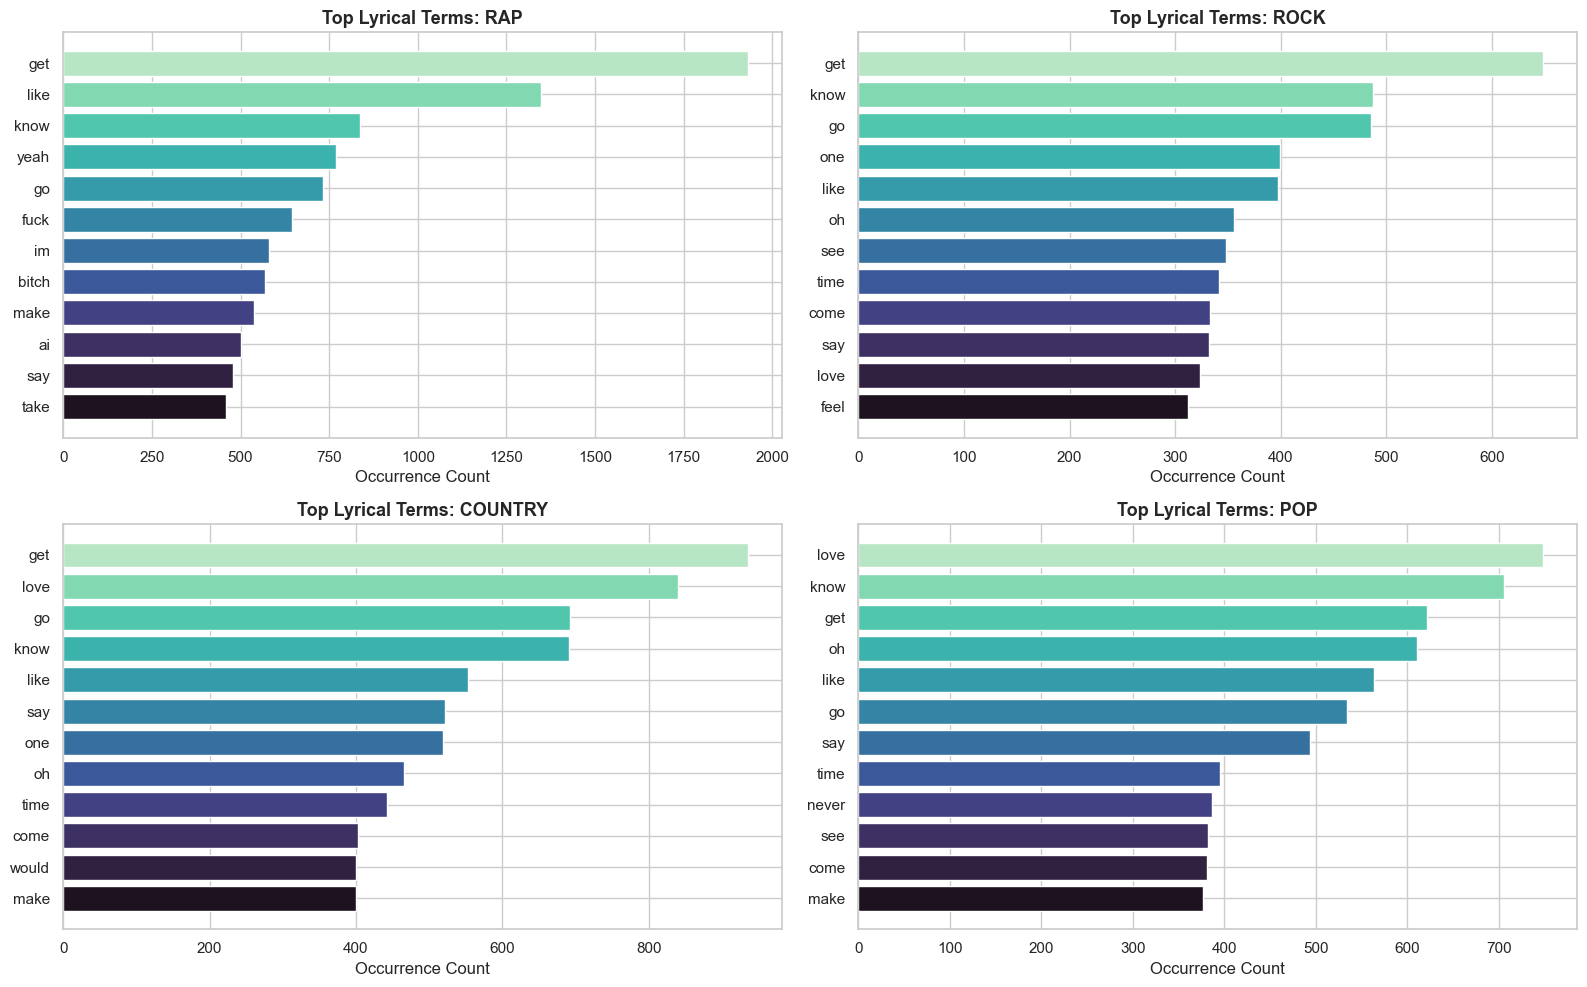

In [9]:
# sample a balanced subset per genre for faster exploration
sample_subset = pd.concat([
    g.sample(min(len(g), 500), random_state=42)
    for _, g in train_df.groupby('tag')
]).reset_index(drop=True)

sample_subset['lyrics_clean'] = sample_subset['lyrics'].apply(
    lambda x: clean_for_classification(x, max_words=300)
)

# extract top terms per genre
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
target_genres = ['rap', 'rock', 'country', 'pop']

for ax, genre in zip(axes.flatten(), target_genres):
    genre_lyrics = sample_subset[sample_subset['tag'] == genre]['lyrics_clean']
    vec = CountVectorizer(max_features=12, ngram_range=(1, 2), token_pattern=r"(?u)\b\w+\b")
    X = vec.fit_transform(genre_lyrics)
    counts = np.asarray(X.sum(axis=0)).flatten()
    words = vec.get_feature_names_out()
    df_top = pd.DataFrame({'word': words, 'count': counts}).sort_values(by='count', ascending=True)
    
    ax.barh(df_top['word'], df_top['count'], color=sns.color_palette('mako', len(df_top)))
    ax.set_title(f"Top Lyrical Terms: {genre.upper()}", fontsize=13, weight='bold')
    ax.set_xlabel("Occurrence Count")

plt.tight_layout()
plt.show()


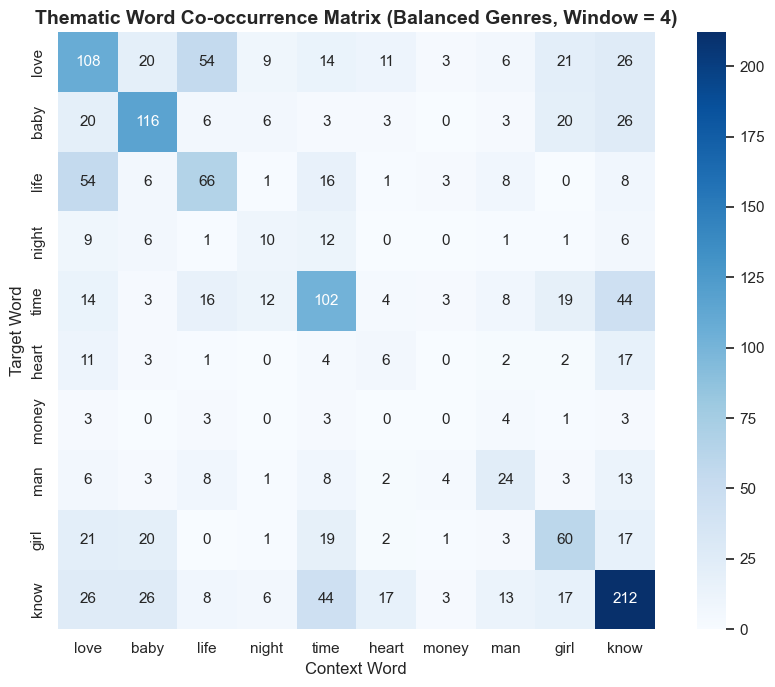

In [10]:
# sample evenly across all 6 genres (50 songs each = 300 songs)
balanced_sample = pd.concat([
    g.sample(min(len(g), 50), random_state=42)
    for _, g in sample_subset.groupby('tag')
]).reset_index(drop=True)

key_terms = ['love', 'baby', 'life', 'night', 'time', 'heart', 'money', 'man', 'girl', 'know']

# tokenize cleaned text
sample_sentences = [text.split() for text in balanced_sample['lyrics_clean'] if text]
cooc_matrix_df = cooccurrence_matrix_sentence_generator(sample_sentences, window_size=4)

# filter to key terms
available_keys = [w for w in key_terms if w in cooc_matrix_df.index]
sub_cooc = cooc_matrix_df.loc[available_keys, available_keys]

plt.figure(figsize=(9, 7))
sns.heatmap(sub_cooc, annot=True, fmt="d", cmap="Blues", cbar=True, square=True)
plt.title("Thematic Word Co-occurrence Matrix (Balanced Genres, Window = 4)", fontsize=14, weight='bold')
plt.xlabel("Context Word")
plt.ylabel("Target Word")
plt.tight_layout()
plt.show()


- Different genres show distinct vocabularies (e.g. slang terms in rap, emotional/introspective words in rock, storytelling terms in country).
- Common words like `love`, `baby`, and `heart` form strong co-occurrence clusters across genres.


## 9. Metadata: Release Years, Views, and Features


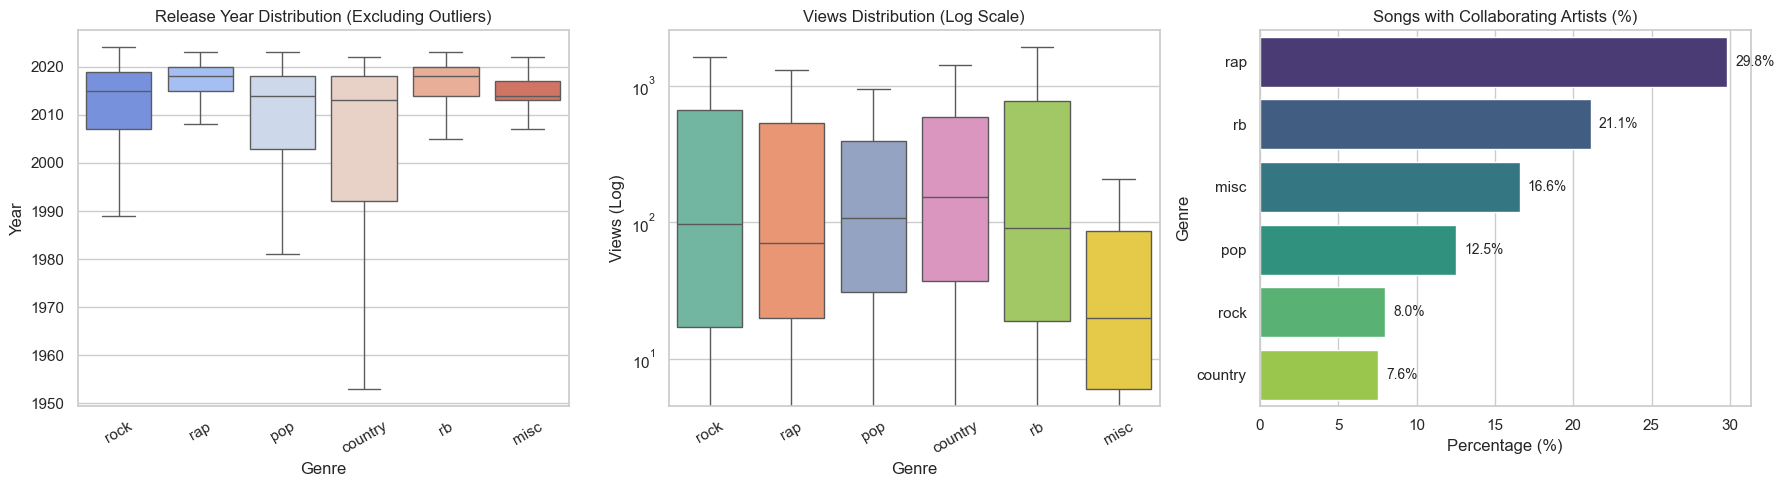

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. release year distribution (1950 to 2025)
valid_years_df = train_df[(train_df['year'] >= 1950) & (train_df['year'] <= 2025)]
sns.boxplot(data=valid_years_df, x='tag', y='year', ax=axes[0], palette='coolwarm', showfliers=False)
axes[0].set_title('Release Year Distribution (Excluding Outliers)')
axes[0].set_xlabel('Genre')
axes[0].set_ylabel('Year')
axes[0].tick_params(axis='x', rotation=30)

# 2. views distribution (log scale)
sns.boxplot(data=train_df, x='tag', y='views', ax=axes[1], palette='Set2', showfliers=False)
axes[1].set_yscale('log')
axes[1].set_title('Views Distribution (Log Scale)')
axes[1].set_xlabel('Genre')
axes[1].set_ylabel('Views (Log)')
axes[1].tick_params(axis='x', rotation=30)

# 3. collaboration rates
train_df['has_features'] = train_df['features'].apply(
    lambda x: x != '{}' and pd.notnull(x) and str(x).strip() != ''
)
collab_rate = (train_df.groupby('tag')['has_features'].mean() * 100).sort_values(ascending=False)
sns.barplot(x=collab_rate.values, y=collab_rate.index, ax=axes[2], palette='viridis')
axes[2].set_title('Songs with Collaborating Artists (%)')
axes[2].set_xlabel('Percentage (%)')
axes[2].set_ylabel('Genre')
for i, v in enumerate(collab_rate.values):
    axes[2].text(v + 0.5, i, f"{v:.1f}%", va='center', fontsize=10)

plt.tight_layout()
plt.show()


### Metadata observations:
- Country songs tend to be slightly older on average, while Rap and R&B are more recent.
- Rap (29.8%) and R&B (21.1%) feature collaborations much more frequently than Rock (8.0%) or Country (7.6%).


## 10. Summary of EDA Findings

- **Class Imbalance:** Pop and Rap make up ~70% of the dataset; Country is under 3%. Stratified splits and Macro-F1 will be essential.
- **Length Differences:** Rap songs are notably longer (median ~415 words) than Rock (median ~188 words). Capping at 1,000 words removes extreme length outliers.
- **Song Structure:** Square-bracket tags like `[Chorus]` appear across most songs and should be stripped during cleaning, while chorus sections can also be extracted separately.
- **Vocabulary:** Genre-specific vocabulary differences and co-occurrence clusters provide clear signals for both genre classification and sentiment analysis.
